# Setup

In [23]:
# Import the updated helpers from the project directory. Reloading picks up
# changes to DEFAULT_FAKE_SCALES without rebuilding the histogram workspace.
import pickle
import numpy as np
import matplotlib.pyplot as plt
import helpers as hp

# Preserve every Matplotlib/Seaborn setting from the original notebook.
hp.configure_pt_plot_style()

In [29]:
def plot_pt_lumi_syst_combined(results, outfile=None, excl_stats=False, fake_model='FakeData', best_fits=None):
    """Plot luminosity-dependent significances using the original notebook styling.

    Curves are evaluated from fitted signal cross sections at each requested
    luminosity; when systematics vanish the same fitted templates are reused.
    """

    # --- Color and Style Mapping ---
    colors_tab = plt.cm.tab20.colors
    color_map = {
        'SM': 'gray',
        'VLF': colors_tab[4],
        'Scalar': colors_tab[0],
        'Zprime': colors_tab[6],
        'Zprime_20pc': 'orangered',
        'FakeData': 'black',
        r'$Z^\prime$ $(\Gamma_{Z^\prime}/M_{Z^\prime} = 0.2)$': 'orangered',
        r'$Z^\prime$ $(\Gamma_{Z^\prime}/M_{Z^\prime} = 0.01)$': colors_tab[6],
        'Pseudo Dataset': 'black',
        'Scalar_1500': colors_tab[0],
        'VLF_1500': colors_tab[4],
        'Zprime_1pc_3000': colors_tab[6],
        'Zprime_3000': 'orangered',
    }

    fig, ax = plt.subplots(figsize=(8, 6))

    pairs = list(results["pair"].unique())

    for pair in pairs:
        sub = results[results["pair"] == pair].sort_values("lumi")
        lumi = sub["lumi"].values
        significance = sub["Z_sh_eps_00"].values
        bsm_name = pair.split(" vs ")[-1] if " vs " in pair else pair

        model_names = {
            'Scalar': 'Scalar', 'VLF': 'VLF',
            'Zprime': r'$Z^\prime$ Narrow',
            'Zprime_20pc': r'$Z^\prime$ Broad',
            'Scalar_1500': 'Scalar', 'VLF_1500': 'VLF',
            'Zprime_1pc_3000': r'$Z^\prime$ Narrow',
            'Zprime_3000': r'$Z^\prime$ Broad',
        }
        display_name = model_names.get(bsm_name, bsm_name)

        model_color = color_map.get(bsm_name, color_map.get(display_name, "tab:purple"))


        ls = "-"

        label_str = f"{display_name}"
        if label_str == 'SM':
            continue       
        if label_str == fake_model:
            continue

        ax.plot(lumi,significance, color=model_color,lw = 3.0, linestyle=ls, label=label_str)

    # --- Formatting the Single Axis ---
    ax.set_ylim([0, 12])
    ax.set_xlim([200,3100])
    ax.axhline(3.0, color='black', linestyle='--', alpha=0.8, linewidth=2.0)
    ax.axhline(2.0, color='black', linestyle='-', alpha=0.8, linewidth=2.0)

    ax.set_ylabel(r"Significance ($Z_A$)", fontsize = 25)
    ax.set_xlabel(rf"Integrated Luminosity $\mathcal{{L}}$ [fb$^{{-1}}$]", fontsize = 25)

    # --- Legend and Titles ---

    handles, labels_ = ax.get_legend_handles_labels()
    by_label = dict(zip(labels_, handles))

    ax.tick_params(axis = 'both', width = 1, labelsize = 25)
    ax.legend(by_label.values(), by_label.keys(),loc="upper left", frameon=False, fontsize = 23., ncols=1)
    ax.set_yticks([2,3,5,7,9,11,13])
    fake_model_str = fake_model
    ax.set_title(r"True Hypothesis ($H_1$):" + f" {fake_model_str}", fontsize = 27)

    plt.tight_layout()

    if outfile is not None:
        fig.savefig(outfile, bbox_inches="tight", dpi=300)
    plt.show()

In [25]:
# Input workspace: one pickle containing SM, fake data, mass-scan templates,
# and independently generated best-fit MC for each BSM truth hypothesis.
workspace_file = 'pT_mass_scan_13_6TeV_hists.pkl'
active_fake_data = 'Scalar_1500'  # 'Scalar_1500', 'VLF_1500', 'Zprime_3000', 'Zprime_1pc_3000', 'SM'


# 'best_fit_mc' uses independent best-fit MC templates; 'grid' uses scanned masses.
# For best_fit_mc, Scalar/VLF are rescaled and reprofiled, whereas both Zprime
# hypotheses already include fitted couplings and should not be reweighted.
mass_source = 'best_fit_mc'
refit_scale = True
refit_zprime_scale = False
analysis_range = (500, 3600)  # GeV, inclusive lower edge / exclusive upper edge
luminosities = np.array([300, 500, 1000, 1500, 2000, 2500, 3000], dtype=float)


fitted_data_dict = {}
for active_fake_data in ['Scalar_1500', 'VLF_1500', 'Zprime_3000']:
    # Couplings of synthetic benchmarks are only defined in hp.DEFAULT_FAKE_SCALES.
    # At zero systematics the best-fit mass/couplings are luminosity independent:
    # helpers performs one fit and reuses the templates for the entire luminosity scan.
    # For any nonzero systematic, it re-fits every luminosity separately.
    with open(workspace_file, 'rb') as handle:
        workspace = pickle.load(handle)
    benchmark_keys = [key for key in workspace['FakeData'] if key != 'SM']

    fitted_data_by_lumi = hp.assemble_luminosity_fits(
        fake_data_key=active_fake_data, workspace_file=workspace_file,
        luminosities=luminosities, systematics=[0.0],
        observable='pT', analysis_range=analysis_range,
        mass_source=mass_source, refit_best_fit_scale=refit_scale,
        refit_zprime_best_fit_scale=refit_zprime_scale,
    )
    fitted_data_dict[active_fake_data] = fitted_data_by_lumi

Fitting Scalar_1500 once at 300 fb^-1 (0% systematics).

Fitting observable: pT
Analysis range: 500 <= pT < 3600 GeV
Systematic error: 0.0%
VLF         : selected mass = 1744.000 GeV | parabolic estimate = 1744.502 GeV | scale = 4.5628717 | chi2(500/fb) = 0.845848 (31 bins) | source = best_fit_mc
Scalar      : selected mass = 1510.000 GeV | parabolic estimate = 1510.184 GeV | scale = 7.5777179 | chi2(500/fb) = 0.00877195 (31 bins) | source = best_fit_mc
Zprime      : selected mass = 2500.000 GeV | parabolic estimate = 2500.067 GeV | scale = -0.33389007 | chi2(500/fb) = 23.2898 (31 bins) | source = best_fit_mc
Zprime_20pc : selected mass = 2882.000 GeV | parabolic estimate = 2882.792 GeV | scale = -3.837104 | chi2(500/fb) = 10.4665 (31 bins) | source = best_fit_mc
FakeData    : nominal mass = 1500.0 GeV | scale = 7.5
Synthetic signal yield in fit window: 1812.67 events
Fitting VLF_1500 once at 300 fb^-1 (0% systematics).

Fitting observable: pT
Analysis range: 500 <= pT < 3600 GeV
Syste

# Significance versus luminosity

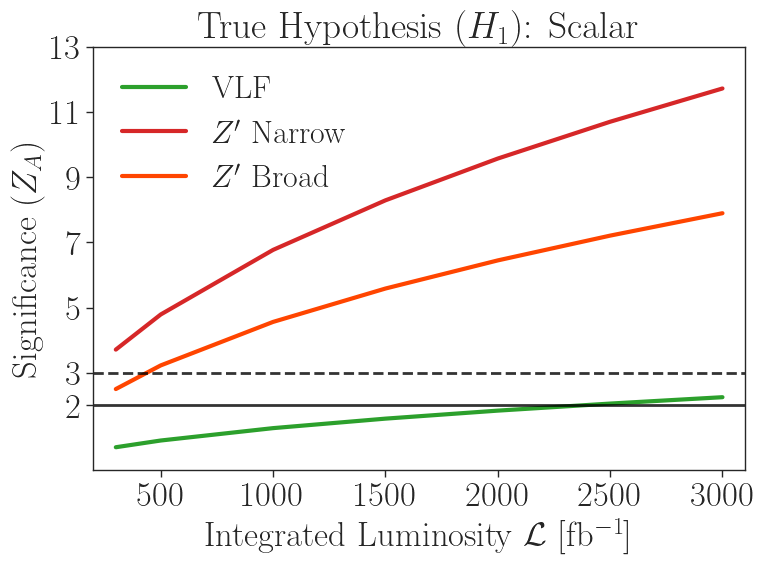

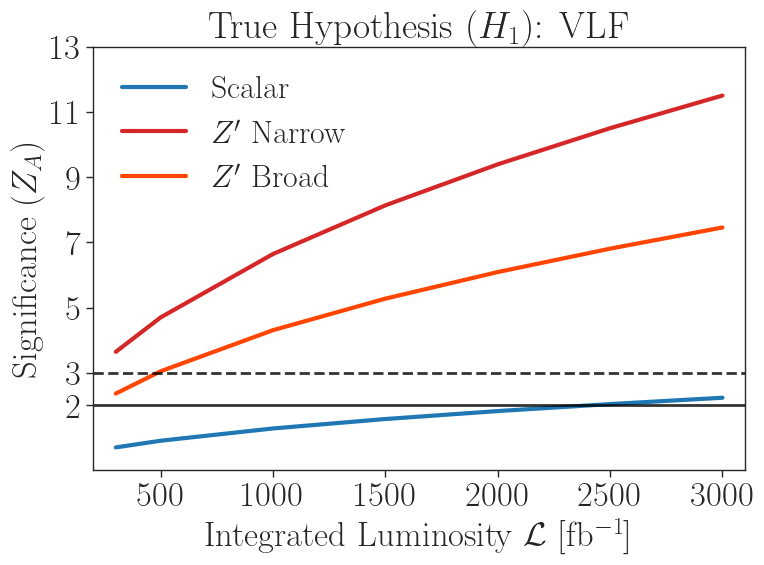

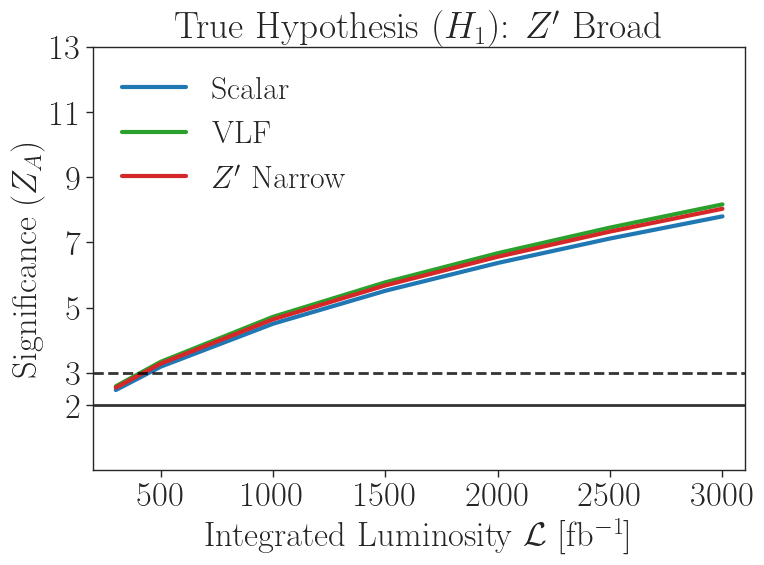

In [30]:
for active_fake_data in ['Scalar_1500', 'VLF_1500', 'Zprime_3000']:

    # The fit scan and profile-likelihood computations stay in helpers.py.
    # At zero systematics, helpers reuses one set of fitted masses/couplings.
    results_df = hp.scan_truth_significances(
        active_fake_data, fitted_data_dict[active_fake_data], luminosities, [0.0],
        benchmark_keys, observable='pT', analysis_range=analysis_range,
    )


    # Display names are editable here without changing the statistical model keys.
    true_model_labels = {
        'Scalar_1500': 'Scalar', 'VLF_1500': 'VLF',
        'Zprime_3000': r'$Z^\prime$ Broad',
        'Zprime_1pc_3000': r'$Z^\prime$ Narrow', 'SM': 'SM',
    }


    plot_pt_lumi_syst_combined(
        results=results_df,
        outfile=f'./../paper_plots/AsimovSignificance_vs_Lumi_{active_fake_data.split("_")[0]}.png',
        fake_model=true_model_labels[active_fake_data],
    )
